# 05 — Modeling & Model Comparison

BQ01: dự đoán giá rao bán BĐS TP.HCM. Notebook trình bày kết quả được tạo bởi pipeline module hóa, không chứa business logic trùng lặp.

In [1]:
from pathlib import Path
import sys, json, pandas as pd
from IPython.display import display, Image
PROJECT_ROOT = Path.cwd().resolve().parent if Path.cwd().name == 'notebooks' else Path.cwd().resolve()
sys.path.insert(0, str(PROJECT_ROOT/'src'))
REPORT = PROJECT_ROOT/'reports/modeling'
FIG = PROJECT_ROOT/'reports/figures'

## 1. Modeling data audit

In [2]:
audit = json.loads((REPORT/'modeling_data_audit.json').read_text(encoding='utf-8'))
audit

{'source': 'C:\\Users\\LEGION\\Downloads\\DAP_Final_Project_BT1_BT2\\DAP_Final_Project\\data\\processed\\hcm_realestate_cleaned_20260912_163121.parquet',
 'rows': 6086,
 'columns': 36,
 'target': 'price_vnd',
 'target_missing': 0,
 'target_nonpositive': 0,
 'duplicate_listing_id': 0,
 'numeric_features': ['area_m2'],
 'categorical_features': ['property_type', 'legacy_area'],
 'model_features': ['area_m2', 'property_type', 'legacy_area'],
 'feature_count': 3}

## 2. Feature selection & leakage policy

In [3]:
features = pd.read_csv(REPORT/'feature_selection_report.csv')
features.loc[features['used_in_model'] == True, ['feature','dtype','missing_rate','reason']]

,feature,dtype,missing_rate,reason
0,area_m2,float64,0.0,"Đủ availability, có ý nghĩa dự báo và không gâ..."
1,legacy_area,str,0.0,"Đủ availability, có ý nghĩa dự báo và không gâ..."
2,property_type,str,0.0,"Đủ availability, có ý nghĩa dự báo và không gâ..."


Preprocessing được đặt trong `Pipeline/ColumnTransformer` và chỉ fit trên train. Không dùng target-derived feature như giá/m², price_text, price_billion, log_price_vnd hay identifier/text.

## 3. Model comparison

In [4]:
comparison = pd.read_csv(REPORT/'model_comparison.csv')
view = comparison.copy()
for c in ['CV_MAE_mean','CV_MAE_std','Train_MAE','Test_MAE','Train_RMSE','Test_RMSE','Generalization_gap_MAE']:
    view[c] = view[c] / 1e9
view

,Model,CV_MAE_mean,CV_MAE_std,Train_MAE,Test_MAE,Train_RMSE,Test_RMSE,Train_R2,Test_R2,Generalization_gap_MAE,Training_time_seconds,Tuned_with_CV
0,Random Forest,16.955952,1.761197,15.037907,16.576211,43.414314,47.707332,0.560305,0.450738,1.538304,1.4844,True
1,Decision Tree,17.175936,1.667598,15.158803,18.038137,44.083249,51.667543,0.546650,0.355764,2.879334,1.5861,True
2,Dummy Median,22.581885,1.335283,22.581587,23.775642,67.964210,67.219262,-0.077573,-0.090428,1.194055,0.0222,False
3,Ridge,24.807997,1.104987,24.591148,25.906922,59.509575,59.368005,0.173848,0.149422,1.315774,2.8160,True
4,Linear Regression,25.182501,1.111675,24.912196,26.285838,59.464391,59.355965,0.175102,0.149767,1.373642,0.0119,False


In [5]:
meta = json.loads((PROJECT_ROOT/'models/model_metadata.json').read_text(encoding='utf-8'))
print('Final model:', meta['final_model'])
print(f"Test MAE: {meta['test_mae']/1e9:.2f} tỷ VNĐ")
print(f"Test RMSE: {meta['test_rmse']/1e9:.2f} tỷ VNĐ")
print(f"Test R²: {meta['test_r2']:.3f}")
print('Best params:', meta['best_params'])

Final model: Random Forest
Test MAE: 16.58 tỷ VNĐ
Test RMSE: 47.71 tỷ VNĐ
Test R²: 0.451
Best params: {'model__n_estimators': 160, 'model__min_samples_leaf': 8, 'model__max_features': 0.7, 'model__max_depth': None}


## 4. Actual vs predicted, residuals và model comparison

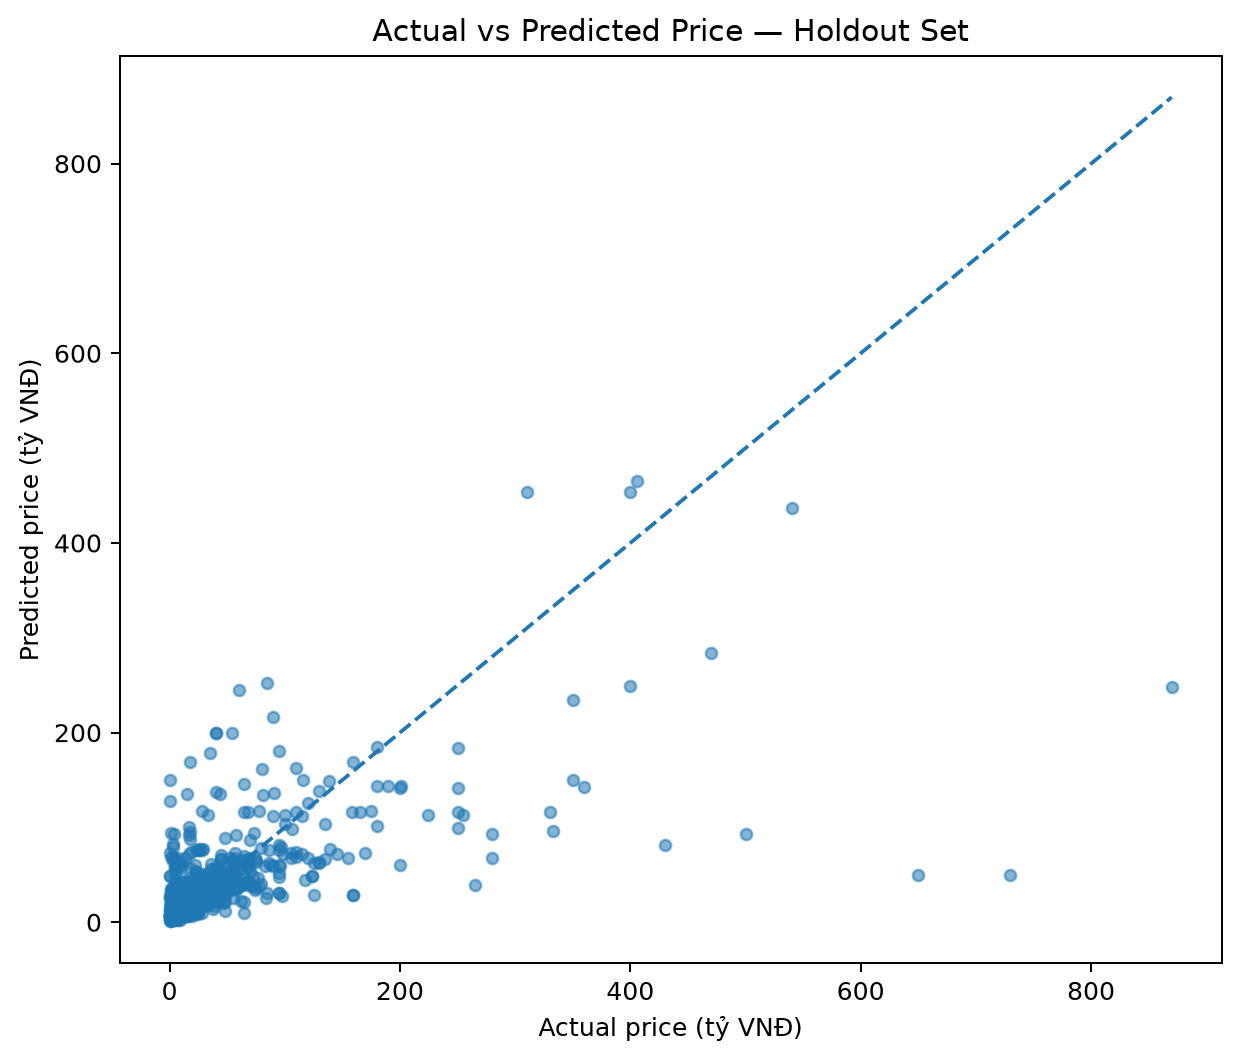

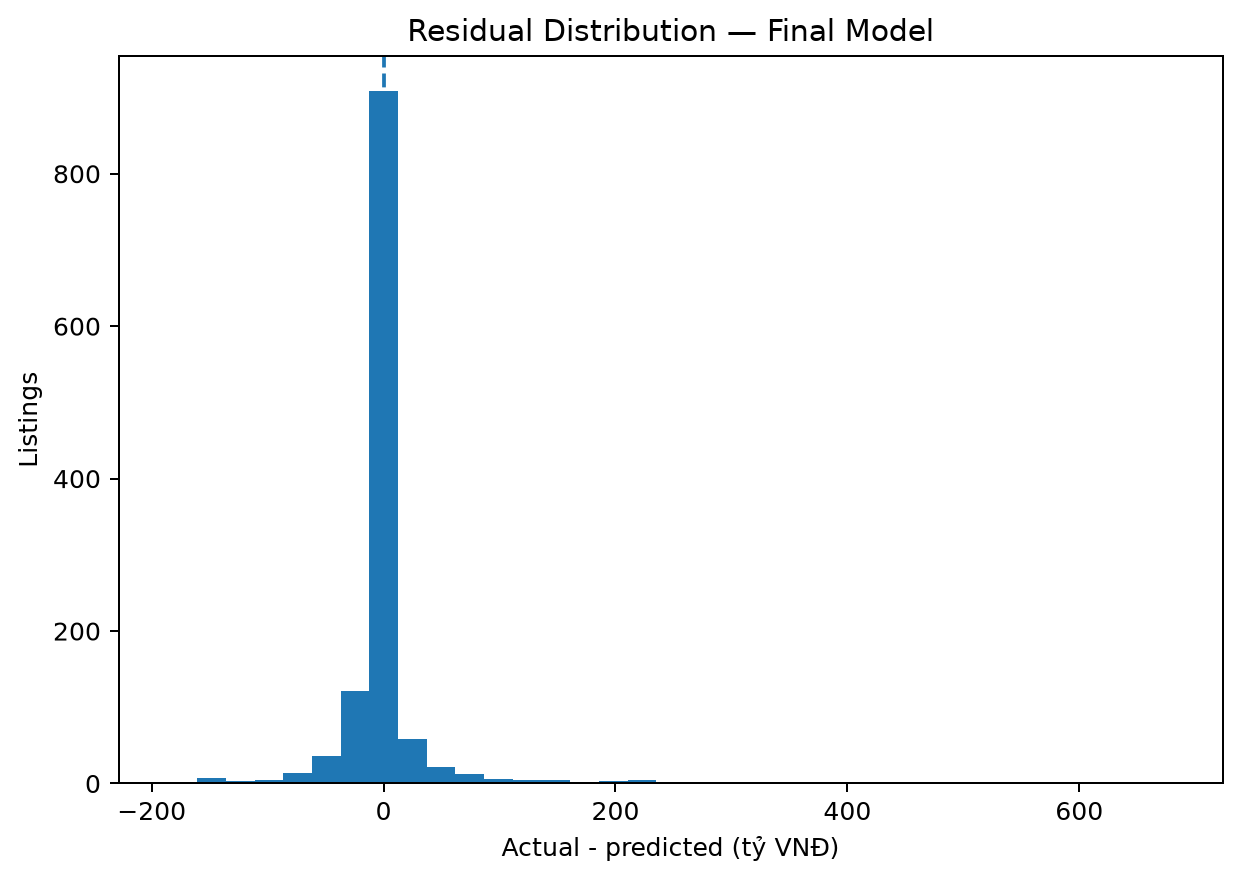

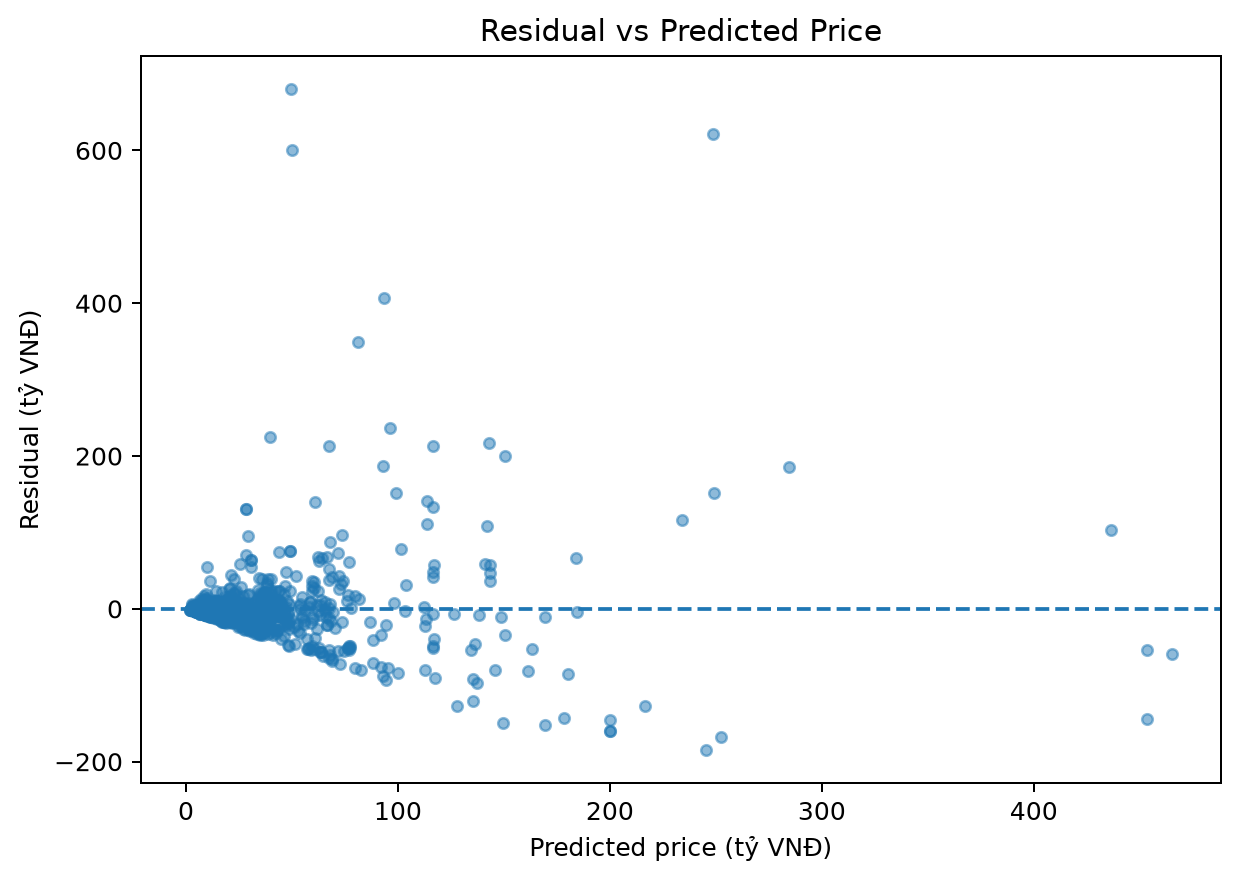

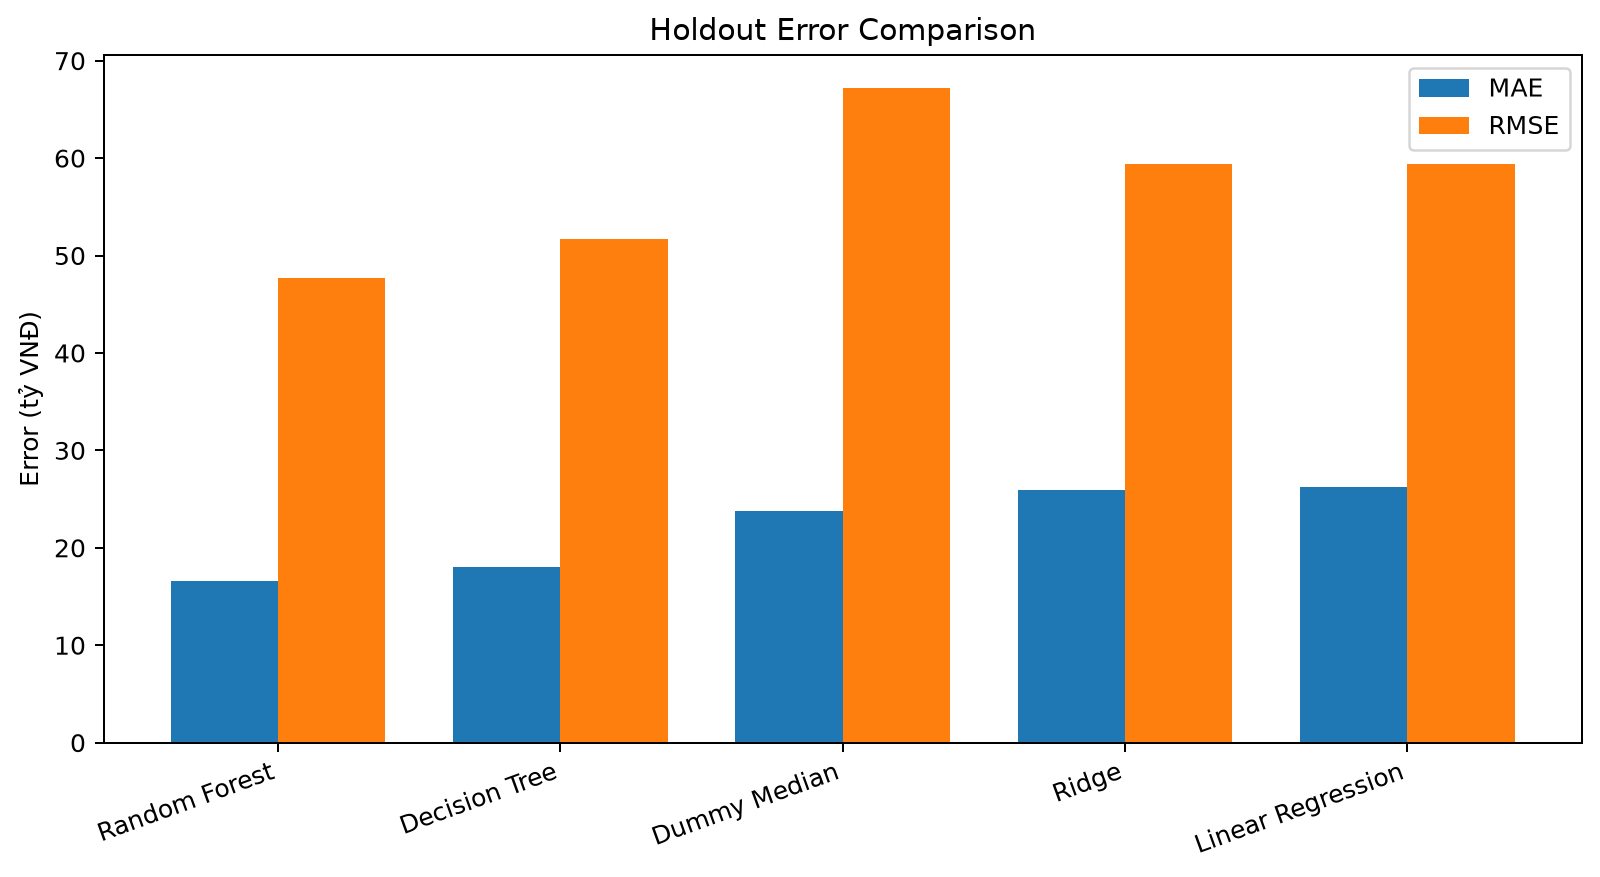

In [6]:
for name in ['15_model_actual_vs_predicted.png','16_model_residual_distribution.png','17_model_residual_vs_predicted.png','18_model_comparison.png']:
    display(Image(filename=str(FIG/name), width=760))

## 5. Bias–variance / learning curves

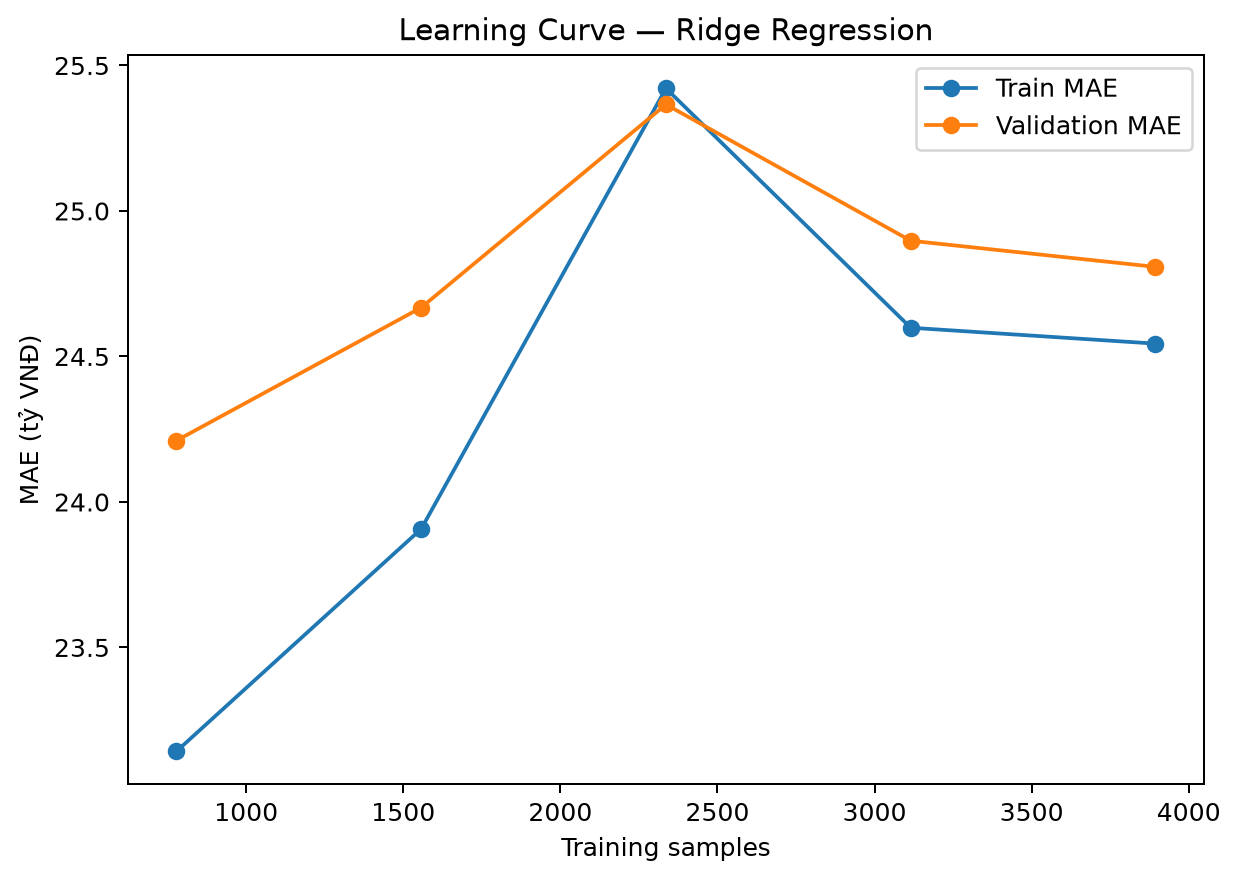

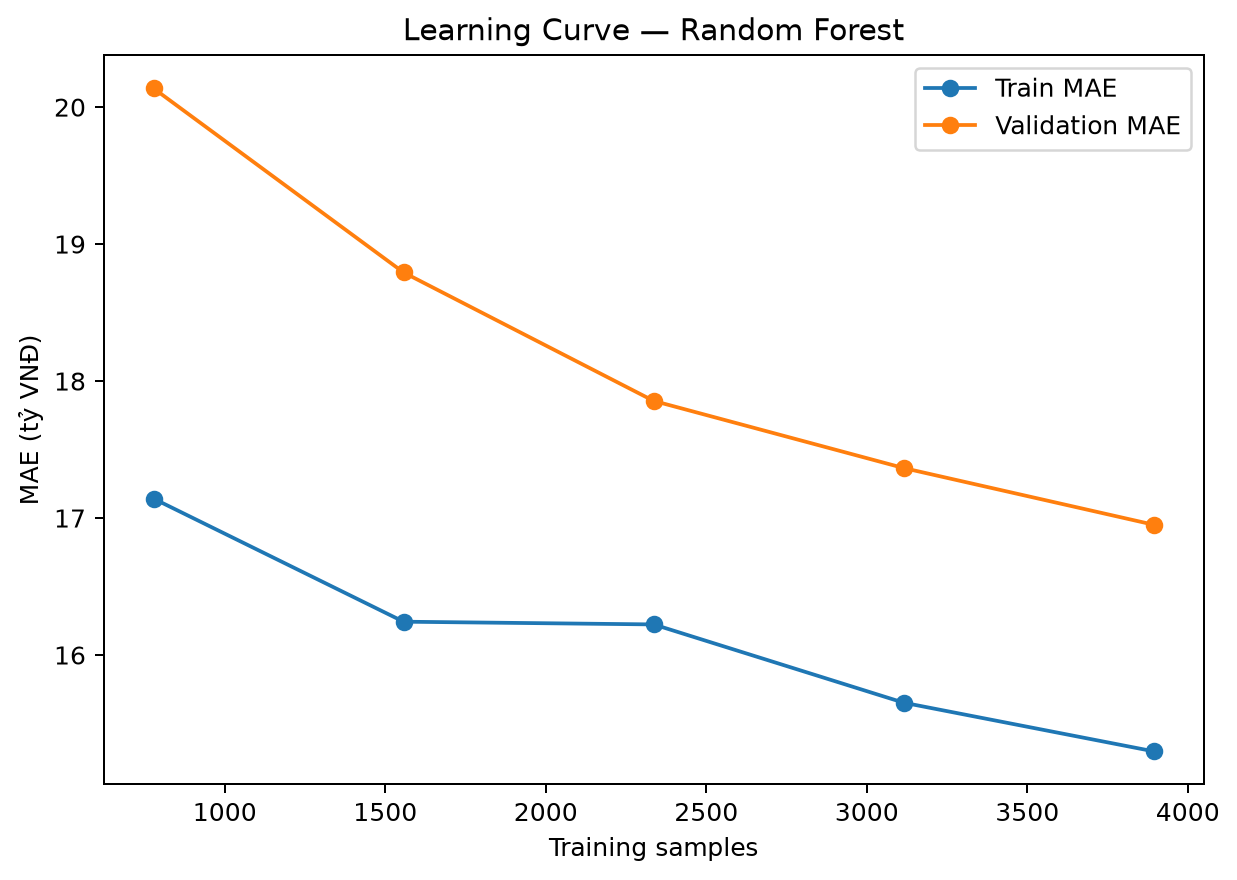

In [7]:
display(Image(filename=str(FIG/'19_ridge_learning_curve.png'), width=760))
display(Image(filename=str(FIG/'20_nonlinear_learning_curve.png'), width=760))

## 6. Interpretation

In [8]:
importance = pd.read_csv(REPORT/'permutation_importance.csv')
importance.assign(importance_billion=importance['importance_mean_mae']/1e9)

,feature,importance_mean_mae,importance_std,importance_billion
0,area_m2,1.446762e+10,6.125198e+08,14.467621
1,legacy_area,8.795733e+09,3.619047e+08,8.795733
2,property_type,6.204448e+08,5.001314e+07,0.620445


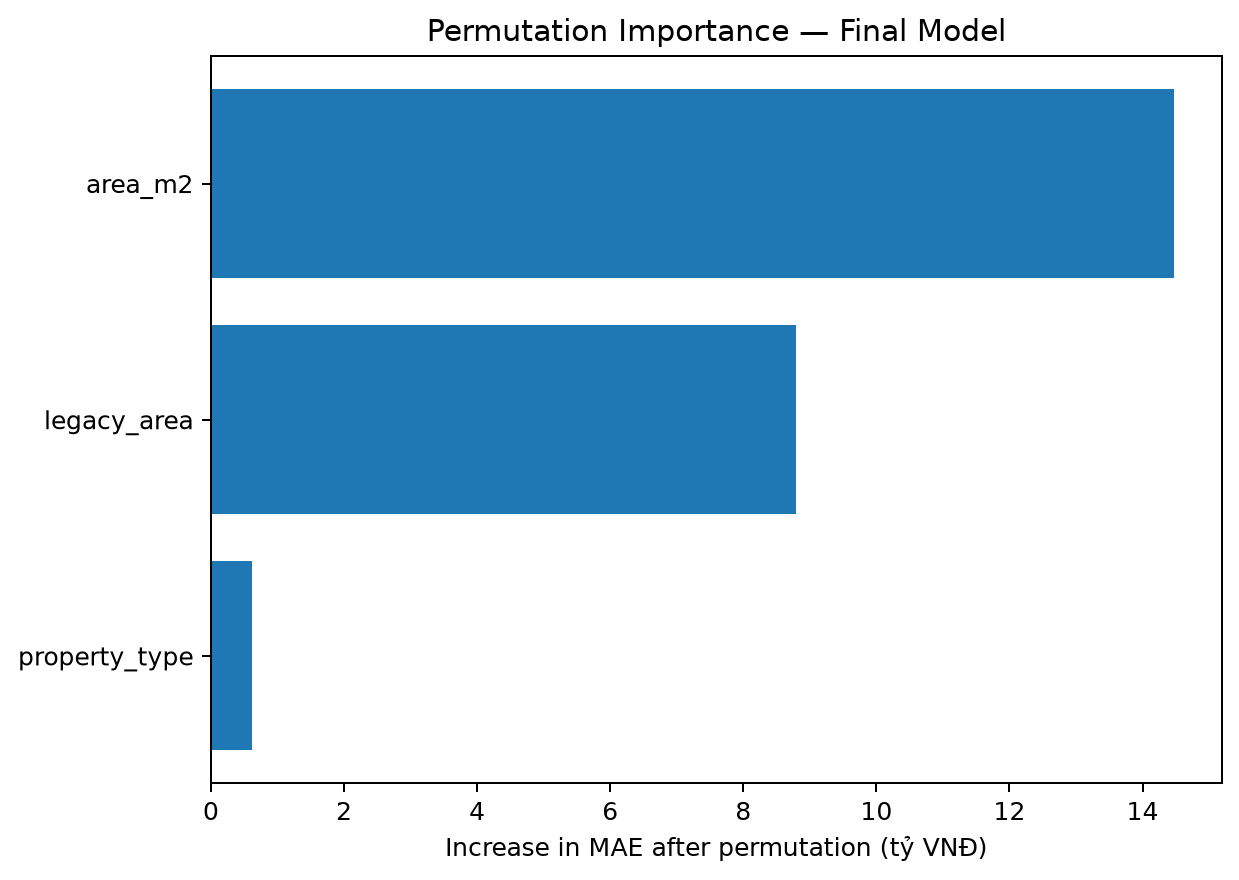

In [9]:
display(Image(filename=str(FIG/'21_permutation_importance.png'), width=760))

Permutation importance đo mức tăng MAE khi phá thông tin của feature trên holdout. Đây là predictive importance, không phải causal effect.

## 7. Error analysis

In [10]:
err_type = pd.read_csv(REPORT/'error_by_property_type.csv')
err_area = pd.read_csv(REPORT/'error_by_legacy_area.csv')
display(err_type.assign(MAE_billion=err_type['MAE']/1e9))
display(err_area.head(10).assign(MAE_billion=err_area.head(10)['MAE']/1e9))

,property_type,rows,MAE,Median_APE,MAE_billion
0,villa,35,4.695210e+10,32.688853,46.952096
1,land,134,3.118843e+10,60.604847,31.188428
2,commercial,18,3.081624e+10,40.624291,30.816242
3,house,812,1.429911e+10,33.072786,14.299106
4,unknown,55,1.360947e+10,29.005779,13.609471
5,apartment,164,8.860758e+09,45.786448,8.860758


,legacy_area,rows,MAE,Median_APE,MAE_billion
0,Quận 1,89,4.803584e+10,57.045663,48.035839
1,Quận 3,50,2.712832e+10,33.006472,27.128318
2,Quận 5,38,2.699290e+10,56.913097,26.992897
3,TP Thủ Đức,181,2.585557e+10,38.003984,25.855570
4,Quận 10,41,1.896384e+10,35.499327,18.963840
5,Quận 7,120,1.709298e+10,34.821409,17.092975
6,Quận Bình Thạnh,71,1.484421e+10,32.568327,14.844206
7,Quận Phú Nhuận,66,1.344397e+10,33.104906,13.443975
8,Huyện Củ Chi,31,1.240336e+10,236.537580,12.403362
9,Quận 4,6,1.238499e+10,60.693130,12.384985


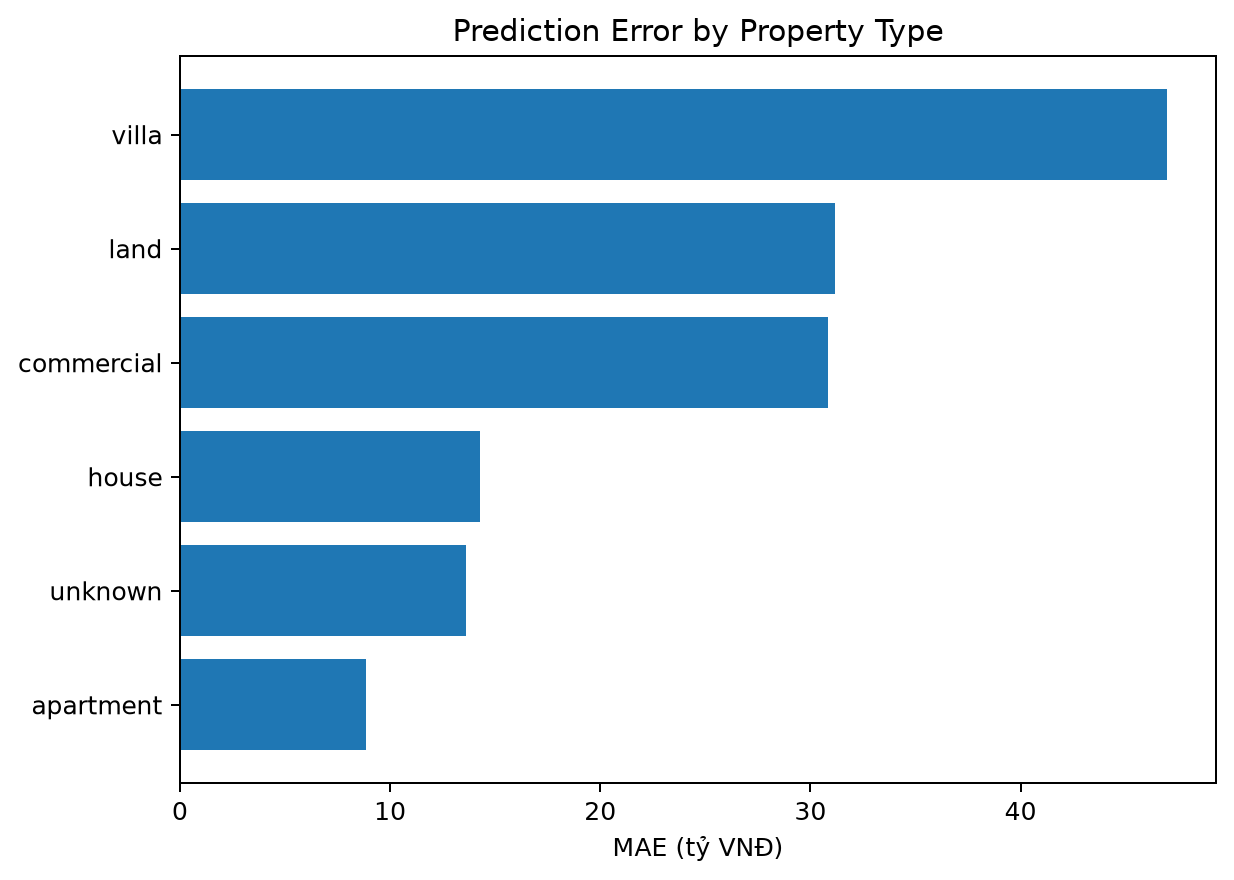

In [11]:
display(Image(filename=str(FIG/'22_error_by_property_type.png'), width=760))

## 8. Business interpretation & limitations

Model dùng cho tham khảo định giá nhanh trên giá rao CafeLand. Sai số vẫn lớn ở một số loại hình/khu vực, target không phải giá giao dịch, feature vị trí còn ở mức quận/huyện và card-only crawl thiếu thuộc tính chi tiết. Vì vậy kết quả không thay thế thẩm định giá chuyên nghiệp.

## 9. Reproducibility

Chạy từ project root: `python scripts/run_all.py --stage modeling`. Artifact cuối: `models/best_price_model.joblib`; metrics: `reports/modeling/`; demo: `streamlit run app/app.py`.

In [12]:
# Optional: retrain toàn bộ pipeline khi cần
RUN_TRAINING = False
if RUN_TRAINING:
    from dap_project.pipelines.modeling import run_modeling
    result = run_modeling(PROJECT_ROOT)
    result